First 5 records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target Classes: ['setosa' 'versicolor' 'virginica']

Model Performance Comparison:
        Model  Accuracy  Precision  Recall  F1 Score
Decision Tree    0.9333     0.9333  0.9333    0.9333
Random Forest    0.9000     0.9024  0.9000    0.8997


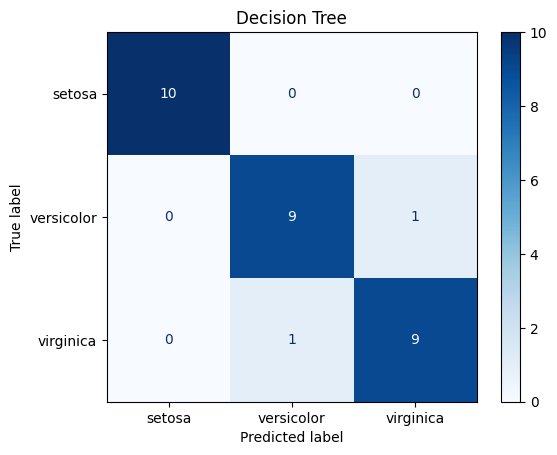

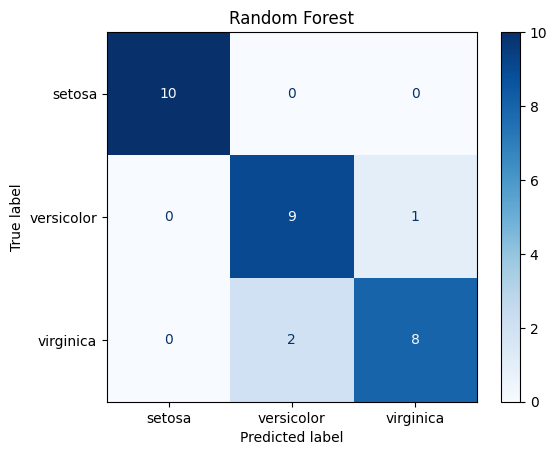

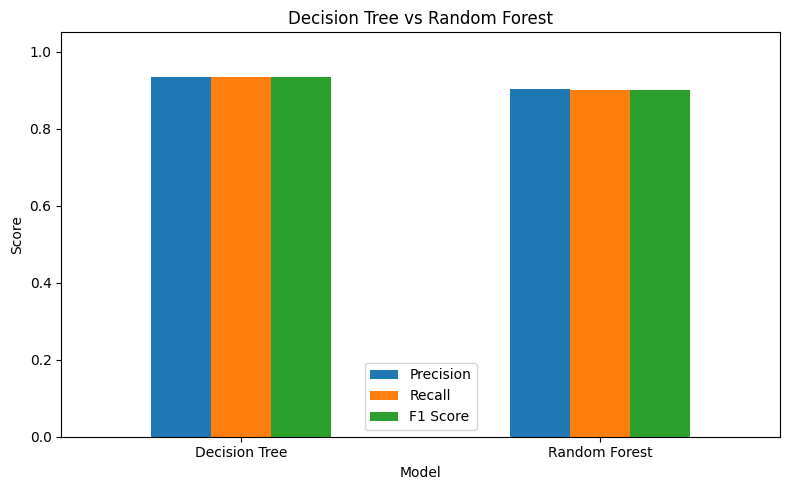

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, ConfusionMatrixDisplay, confusion_matrix
)

# 1. Load dataset
data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("First 5 records:")
print(X.head())

print("\nTarget Classes:", data.target_names)

# 2. Create a common train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini", random_state=42
)
dt_model.fit(X_train, y_train)

# 4. Train Random Forest on the same training data
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42   #Random Forest will contain 100 Decision Tree
)
rf_model.fit(X_train, y_train)

# 5. Predict test data
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# 6. Evaluate both models
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(actual, predicted), 4),
        "Precision": round(precision_score(
            actual, predicted, average="macro", zero_division=0
        ), 4),
        "Recall": round(recall_score(
            actual, predicted, average="macro", zero_division=0
        ), 4),
        "F1 Score": round(f1_score(
            actual, predicted, average="macro", zero_division=0
        ), 4)
    }

results = pd.DataFrame([
    evaluate_model("Decision Tree", y_test, dt_pred),
    evaluate_model("Random Forest", y_test, rf_pred)
])

print("\nModel Performance Comparison:")
print(results.to_string(index=False))

# 7. Display confusion matrices
# Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred, display_labels=data.target_names,
    cmap="Blues"
)
plt.title("Decision Tree")
plt.show()

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=data.target_names,
    cmap="Blues"
)
plt.title("Random Forest")
plt.show()

# 8. Plot metric comparison
results.set_index("Model")[[
    "Precision", "Recall", "F1 Score"
]].plot(kind="bar", figsize=(8, 5))

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
